# Reading FEM / CFD / engineering-interchange mesh formats

Finite-element solvers, computational-fluid-dynamics codes and the generic
mesh-interchange formats that move geometry between them each write their own
file layout. `pyramids-mesh` ships a driver for every one of them: a driver
parses the file and hands back a **`pyramids.netcdf.ugrid.UgridDataset`** — the
same unstructured-grid object the rest of the pyramids stack understands.

This notebook opens eighteen such formats from the real sample files under
`examples/data/`, inspects each mesh, and plots it two ways: the bare wireframe
and a map coloured by per-cell area. Every format is read with an explicit
`driver="<name>"` so detection is never in play.

**These are engineering meshes, not GIS layers.** A FEM/CFD mesh carries no
coordinate reference system — its vertices live in a model's own
dimensionless or metric design space — so every dataset below reports
`crs=None`. Reading them as `UgridDataset` objects is what makes pyramids'
GIS, sampling and plotting machinery applicable to them in the first place.

## Setup

The first cell fixes a headless Matplotlib backend (`Agg`) so the notebook runs
unattended under `nbconvert`, then switches on the inline backend so figures are
captured into the output. cleopatra's plot methods (reached through pyramids)
return a *glyph* object rather than drawing onto the active pyplot figure, so the
small `show()` helper displays `glyph.fig` — that is what embeds the picture in
the notebook — and then closes it to keep memory flat across eighteen reads.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from pathlib import Path
from IPython.display import display
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")


def show(glyph):
    """Embed a cleopatra glyph's figure in the notebook, then release it."""
    display(glyph.fig)
    plt.close(glyph.fig)

## Eighteen engineering mesh formats

Each format below follows the same three steps:

1. **Read** the sample with `UgridDataset.read_file(path, driver="<name>")`.
2. **Inspect** — print the structure (node / face counts, bounds, CRS) and a
   `summary()` table of a derived per-cell *area* variable.
3. **Plot** — the wireframe outline, then the mesh coloured by cell area.

The per-cell area is attached with `with_variable(...)`: pyramids computes
`mesh.face_areas` from the topology, and once it is a mesh variable the generic
`summary()` and `plot()` paths light up — exactly the point of making these
files readable as `UgridDataset` objects. A few samples are volumetric meshes
flattened to a plane, so some faces collapse to near-zero projected area; that
is expected and left visible rather than hidden.

### 1. Gmsh (`.msh`) — `driver="gmsh"`

Gmsh is the open-source finite-element mesh generator; its `.msh` format (v2.2 and v4.1 here) is read by many FEM solvers. Pure model geometry — no georeferencing, so `crs=None`.

In [2]:
ds = UgridDataset.read_file(str(DATA / "gmsh/insulated-4.1.msh"), driver="gmsh")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\gmsh\insulated-4.1.msh
  Mesh: mesh2d
  Nodes: 67, Faces: 111, Edges: 0
  Bounds: (-2.96649247971263, -2.991611391173865, 3.0, 2.991611391889027)
  CRS: unknown
  Data variables (0):
CRS: None


C:\python-environments\pixi\envs\pyramids-mesh-4081970794675243037\envs\dev\Lib\site-packages\pyramids\netcdf\ugrid\_drivers.py:538: RuntimeWarning: Mesh driver 'dfsu' (pyramids_mesh.drivers.dhi:DfsuDriver) could not be loaded and was skipped: ModuleNotFoundError("No module named 'mikeio'")
  driver = _instantiate(entry_point)


,count,min,max,mean,std
variable,,,,,
cell_area,111,0.178301,0.38836,0.25094,0.049831


Wireframe outline, then the same mesh coloured by per-cell area:

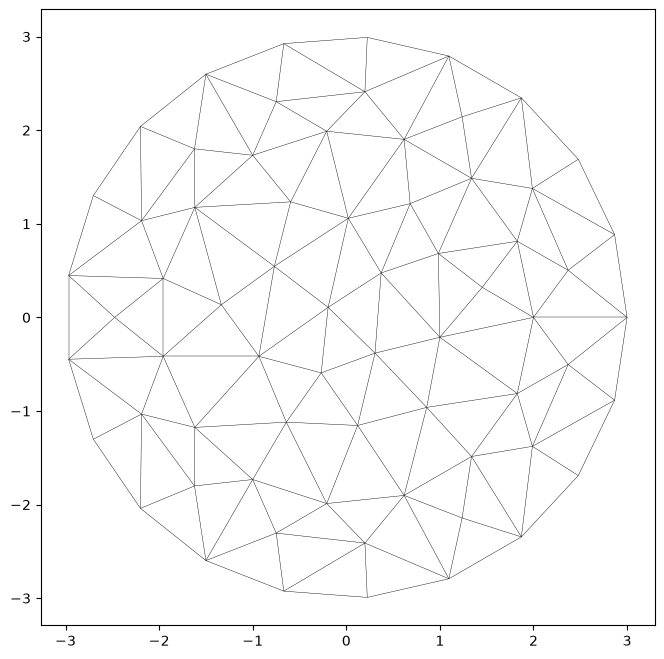

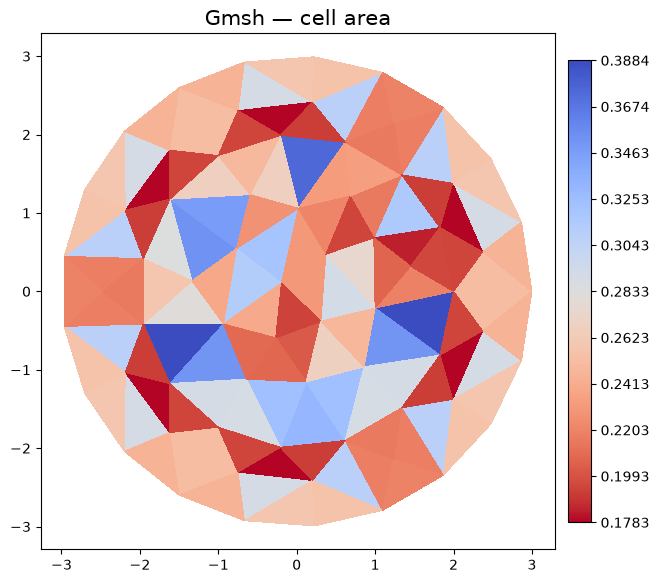

In [3]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="Gmsh — cell area"))

*111 surface triangles from an insulated-conductor model; the fairly uniform cell areas reflect Gmsh's size-field meshing.*

### 2. VTK legacy (`.vtk`) — `driver="vtk"`

VTK is the visualization toolkit behind ParaView and VisIt; the classic ASCII `.vtk` unstructured grid stores cells by VTK type code. A pure visualisation container, carrying no CRS.

In [4]:
ds = UgridDataset.read_file(str(DATA / "vtk/gh-935.vtk"), driver="vtk")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\vtk\gh-935.vtk
  Mesh: mesh2d
  Nodes: 6, Faces: 2, Edges: 0
  Bounds: (0.0, 0.0, 1.0, 1.0)
  CRS: unknown
  Data variables (0):
CRS: None


,count,min,max,mean,std
variable,,,,,
cell_area,2,0.5,0.5,0.5,0.0


Wireframe outline, then the same mesh coloured by per-cell area:

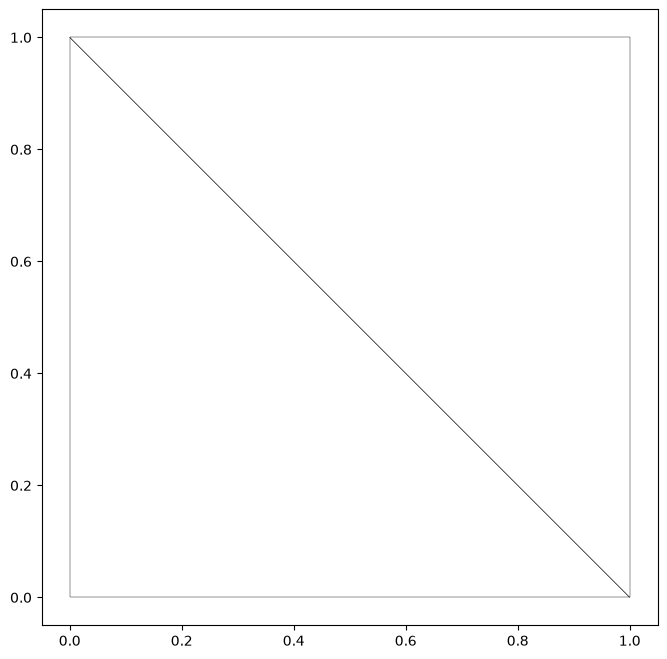

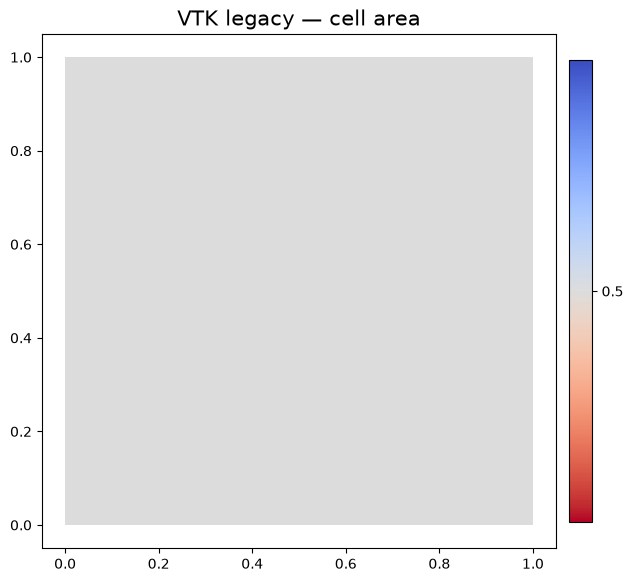

In [5]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="VTK legacy — cell area"))

*A minimal two-triangle grid — useful to confirm the legacy VTK path reads cleanly before trusting it on larger exports.*

### 3. CGNS (`.cgns`) — `driver="cgns"`

CGNS (CFD General Notation System) is the standard CFD interchange format, an HDF5 container holding a SIDS tree. `driver="cgns"` forces the vendored GDAL HDF5 multidimensional driver.

In [6]:
ds = UgridDataset.read_file(str(DATA / "cgns/cgnslib_vers-4400.cgns"), driver="cgns")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\cgns\cgnslib_vers-4400.cgns
  Mesh: mesh2d
  Nodes: 3213, Faces: 1216, Edges: 0
  Bounds: (0.0, 0.0, 20.0, 16.0)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(3213,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 320 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 576 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,3213,0.0,8.0,4.000000,2.581989
cell_area,1216,0.0,1.0,0.526316,0.499307


Wireframe outline, then the same mesh coloured by per-cell area:

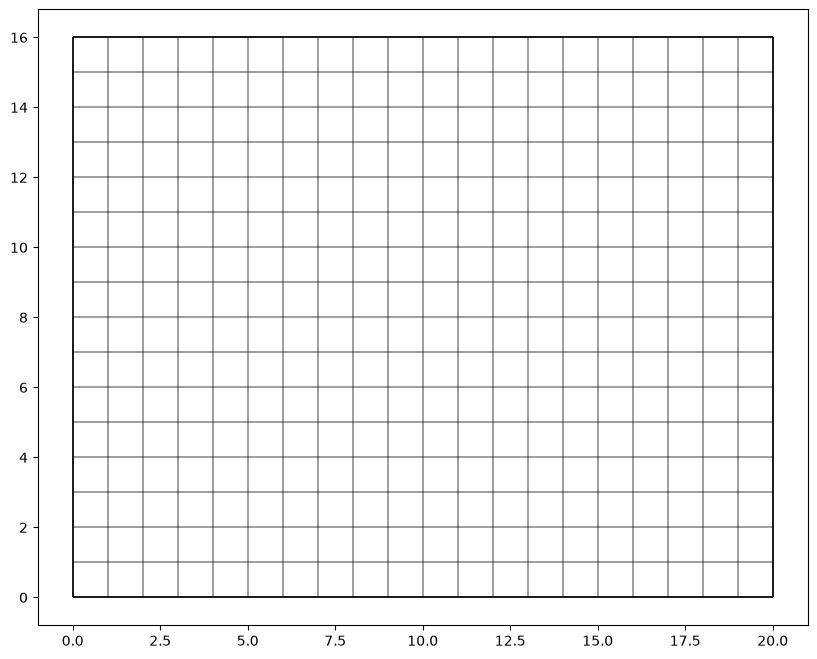

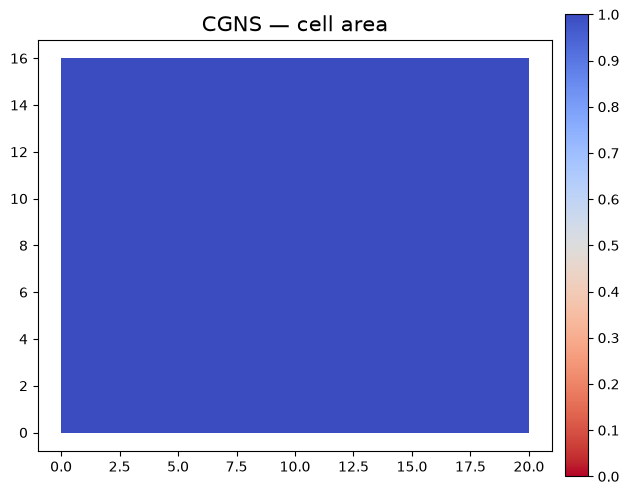

In [7]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="CGNS — cell area"))

*The densest sample here — 1216 faces over 3213 nodes — a realistic CFD surface where the area map exposes local refinement.*

### 4. MED (`.med`) — `driver="med"`

MED is the mesh/field format of Salome and code_aster, also HDF5-based. `driver="med"` forces the HDF5 driver. A solver mesh with no CRS.

In [8]:
ds = UgridDataset.read_file(str(DATA / "med/cylinder.med"), driver="med")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\med\cylinder.med
  Mesh: mesh2d
  Nodes: 33, Faces: 22, Edges: 0
  Bounds: (-1.0, -1.0, 1.0, 1.0)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(33,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 7 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 8 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,33,0.0,1.000000,0.496902,0.408536
cell_area,22,0.0,0.629392,0.257130,0.232027


Wireframe outline, then the same mesh coloured by per-cell area:

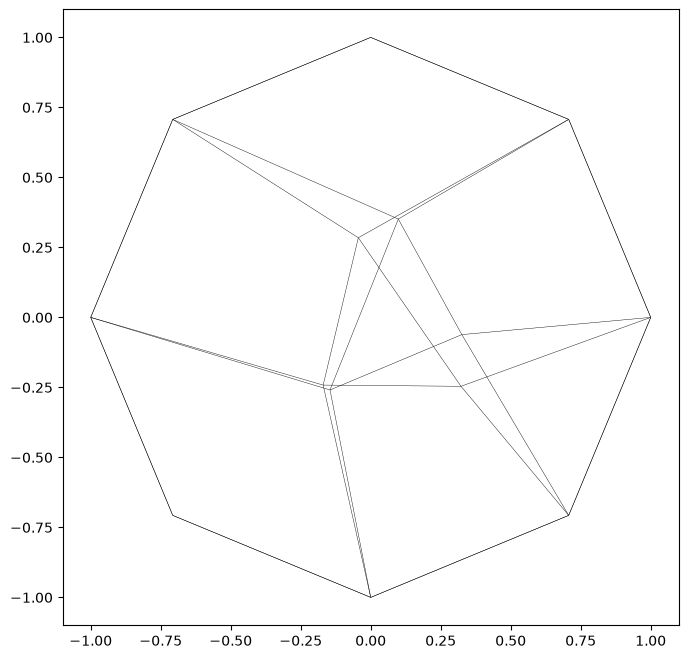

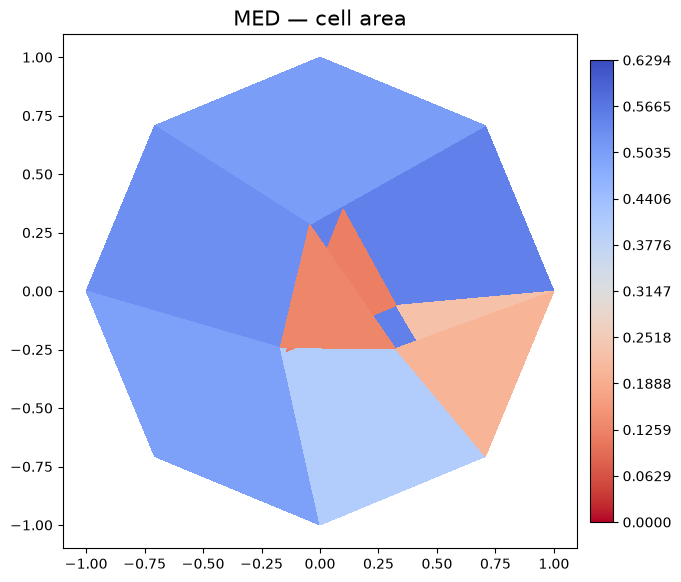

In [9]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="MED — cell area"))

*A mixed triangle+quad surface of a cylinder; blending element shapes in one mesh is routine in Salome and the area summary spans both.*

### 5. Nastran (`.fem`) — `driver="nastran"`

Nastran bulk-data decks (`.fem` / `.bdf`) are the lingua franca of structural FEA. Fixed-field ASCII of `GRID` points and `CTRIA3`/`CQUAD4` elements — design space only, `crs=None`.

In [10]:
ds = UgridDataset.read_file(str(DATA / "nastran/cylinder.fem"), driver="nastran")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\nastran\cylinder.fem
  Mesh: mesh2d
  Nodes: 33, Faces: 22, Edges: 0
  Bounds: (-1.0, -1.0, 1.0, 1.0)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(33,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 7 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 8 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,33,0.0,1.000000,0.496902,0.408536
cell_area,22,0.0,0.629392,0.257130,0.232027


Wireframe outline, then the same mesh coloured by per-cell area:

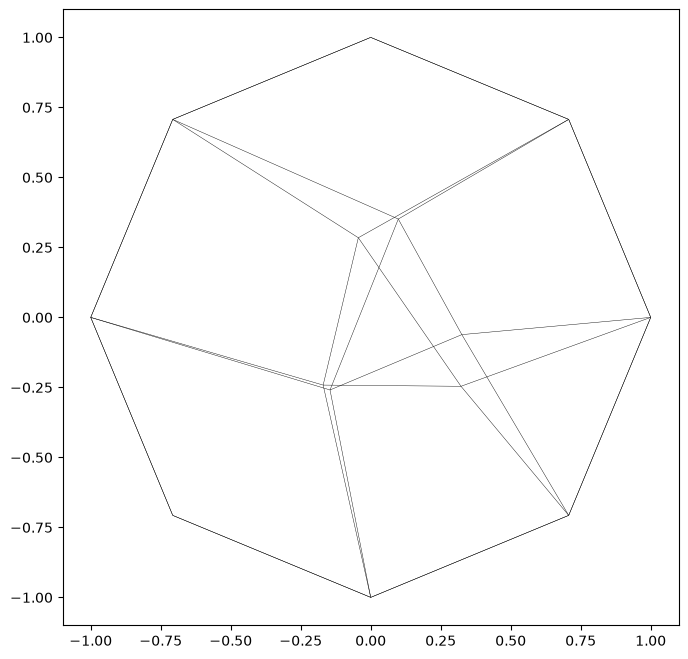

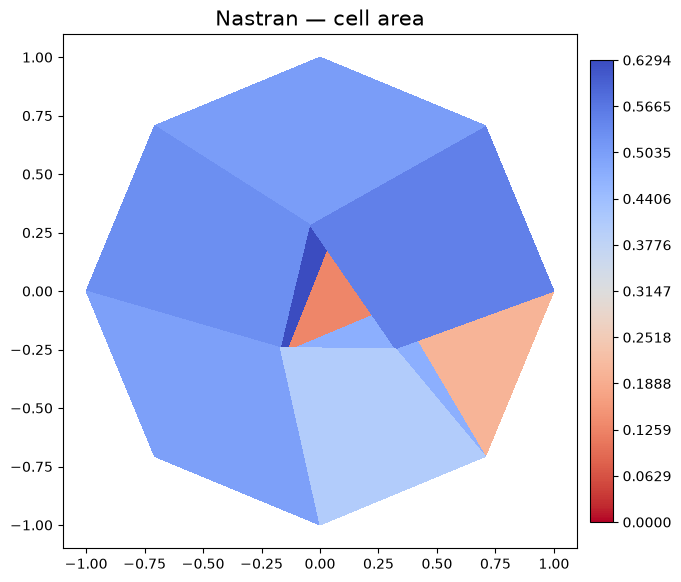

In [11]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="Nastran — cell area"))

*The same cylinder as the MED sample, re-expressed as a Nastran deck — identical 33 nodes / 22 elements, a nice cross-format consistency check.*

### 6. Abaqus (`.inp`) — `driver="abaqus"`

Abaqus keyword decks (`.inp`) drive the Abaqus FEA solver: `*NODE` plus `*ELEMENT` blocks. Here `TYPE=CPS3` plane-stress triangles. No georeferencing.

In [12]:
ds = UgridDataset.read_file(str(DATA / "abaqus/nle1xf3c.inp"), driver="abaqus")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\abaqus\nle1xf3c.inp
  Mesh: mesh2d
  Nodes: 12, Faces: 12, Edges: 0
  Bounds: (0.0, 0.0, 3.25, 2.75)
  CRS: unknown
  Data variables (0):
CRS: None


,count,min,max,mean,std
variable,,,,,
cell_area,12,0.141562,0.780063,0.433391,0.176527


Wireframe outline, then the same mesh coloured by per-cell area:

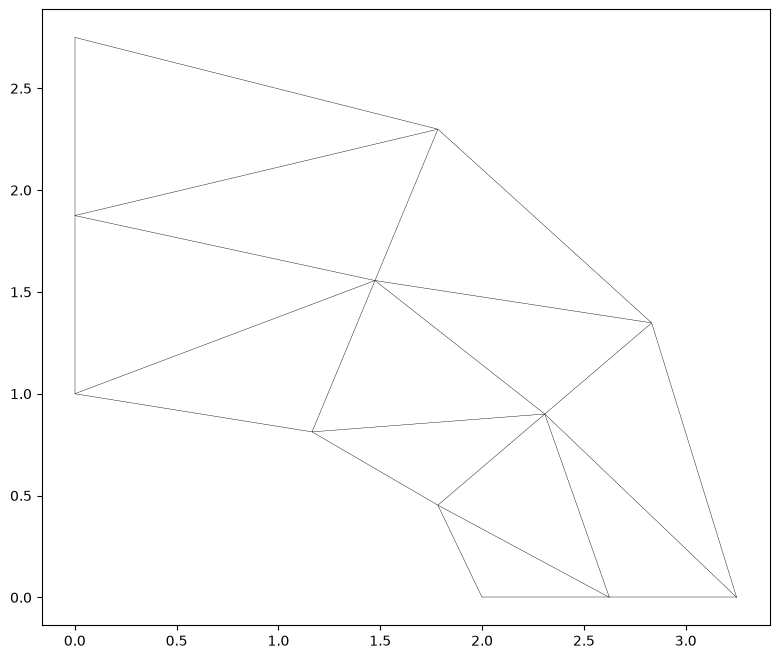

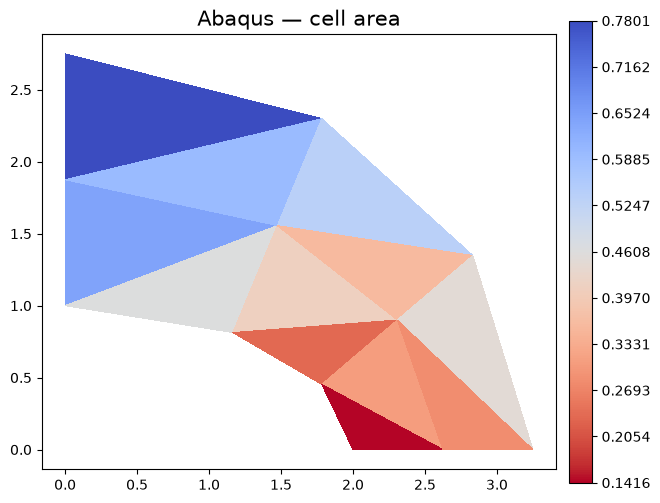

In [13]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="Abaqus — cell area"))

*A small 12-triangle plane-stress patch; the area range shows the graded element sizing typical of a stress-concentration test case.*

### 7. AVS-UCD (`.inp`) — `driver="avsucd"`

AVS-UCD (Unstructured Cell Data) is a generic ASCII interchange format, here a LaGriT export. A visualisation/interchange format with no CRS.

In [14]:
ds = UgridDataset.read_file(str(DATA / "avsucd/02_tet_mesh.inp"), driver="avsucd")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\avsucd\02_tet_mesh.inp
  Mesh: mesh2d
  Nodes: 1122, Faces: 4800, Edges: 0
  Bounds: (0.0, 0.0, 100.0, 50.0)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(1122,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 1877 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 1959 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,1122,0.0,80.0,40.000000,24.494897
cell_area,4800,0.0,100.0,32.822917,29.777821


Wireframe outline, then the same mesh coloured by per-cell area:

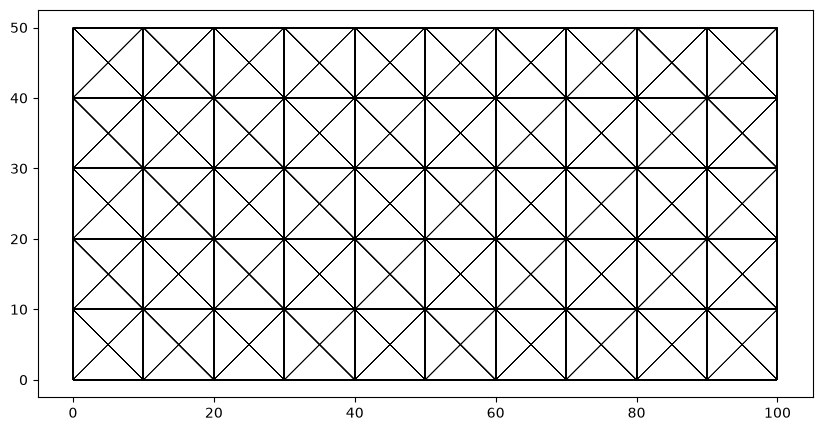

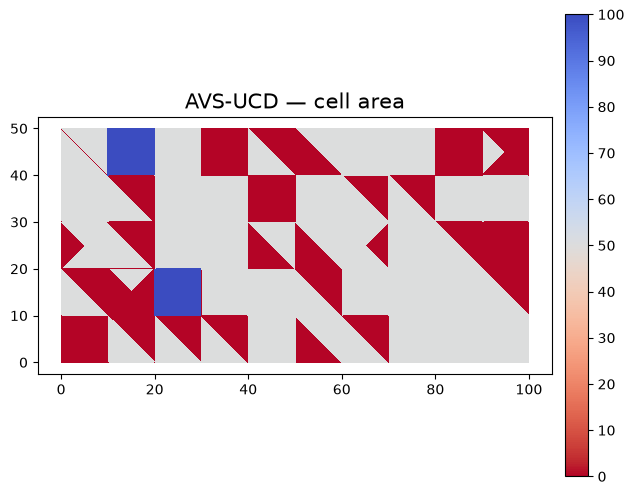

In [15]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="AVS-UCD — cell area"))

*A 4800-element tetrahedral mesh flattened to its face projection — the busiest plot in the notebook; dense tetra projections are kept as-is.*

### 8. Medit (`.mesh`) — `driver="medit"`

Medit `.mesh` is INRIA's simple ASCII format (used by mmg, FreeFEM). Lists `Vertices`, `Triangles` and `Tetrahedra`. A meshing-pipeline format, no CRS.

In [16]:
ds = UgridDataset.read_file(str(DATA / "medit/cube86.mesh"), driver="medit")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\medit\cube86.mesh
  Mesh: mesh2d
  Nodes: 39, Faces: 72, Edges: 0
  Bounds: (0.0, 0.0, 1.0, 1.0)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(39,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 8 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 56 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,39,0.0,1.000000,0.501774,0.359363
cell_area,72,0.0,0.165995,0.027778,0.052637


Wireframe outline, then the same mesh coloured by per-cell area:

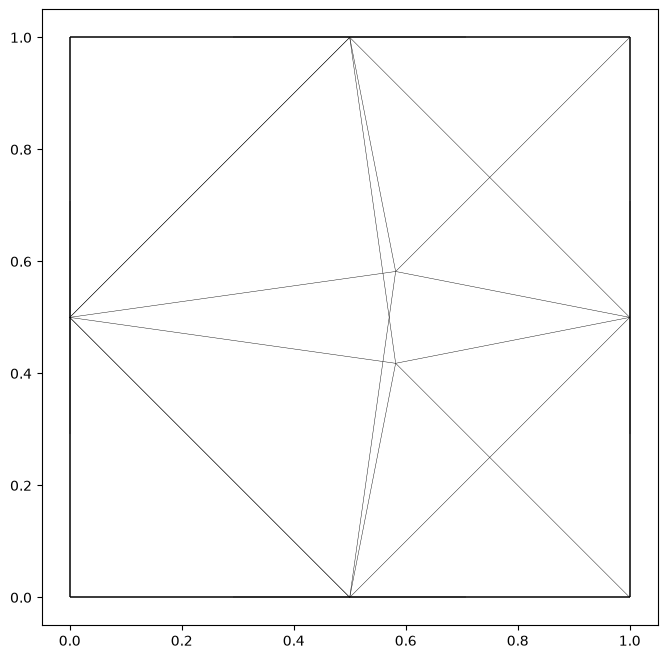

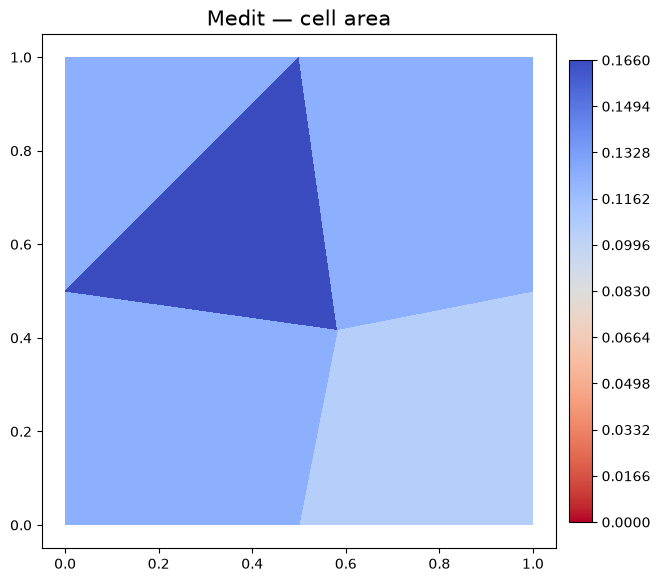

In [17]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="Medit — cell area"))

*72 triangular faces of a unit-cube mesh; the small, even areas reflect a structured subdivision rather than adaptive refinement.*

### 9. Netgen (`.vol`) — `driver="netgen"`

Netgen `.vol` is the native volume-mesh format of the Netgen/NGSolve mesher. Stores surface and volume elements together. Model geometry only.

In [18]:
ds = UgridDataset.read_file(str(DATA / "netgen/periodic_3d.vol"), driver="netgen")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\netgen\periodic_3d.vol
  Mesh: mesh2d
  Nodes: 65, Faces: 108, Edges: 0
  Bounds: (0.0, 0.0, 1.0, 1.0)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(65,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 20 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 72 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,65,0.0,1.00000,0.462335,0.372546
cell_area,108,0.0,0.08615,0.018519,0.027622


Wireframe outline, then the same mesh coloured by per-cell area:

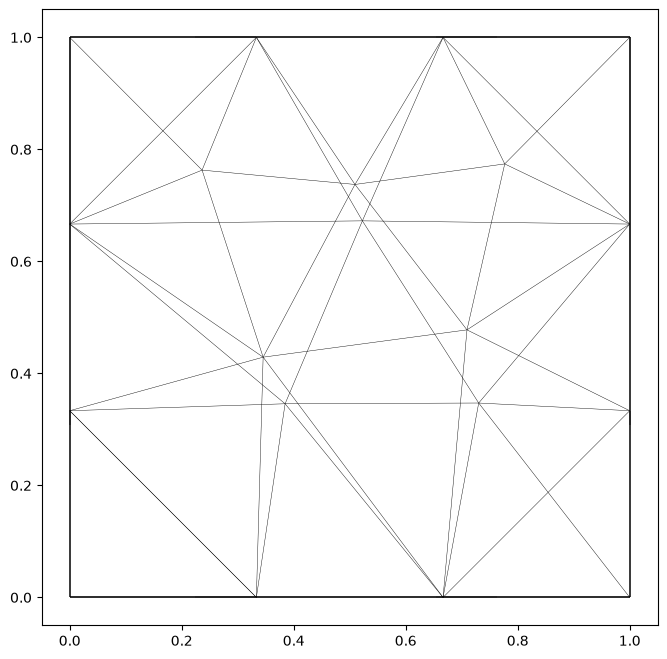

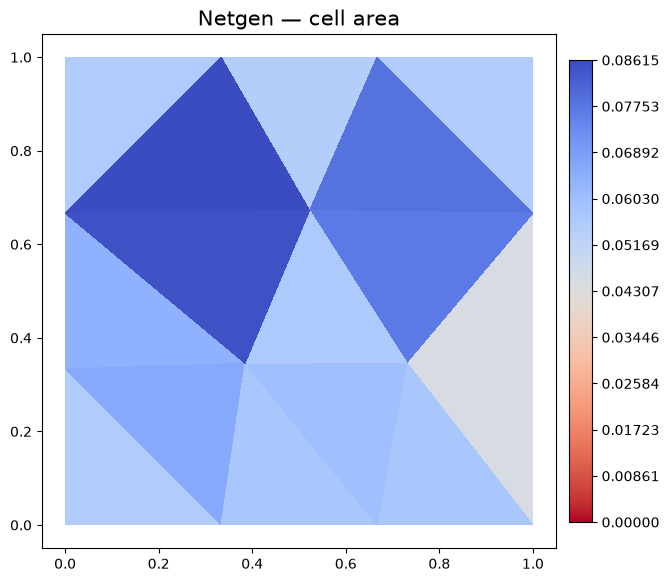

In [19]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="Netgen — cell area"))

*108 surface elements from a periodic 3-D mesh; reading just the surface faces is exactly what the driver exposes to pyramids.*

### 10. Tecplot (`.tec`) — `driver="tecplot"`

Tecplot FE ASCII (`.tec`/`.dat`) is the post-processing format of Tecplot 360, organised into `ZONE`s. Here a single `FEBLOCK` quad zone. A plotting format, no CRS.

In [20]:
ds = UgridDataset.read_file(str(DATA / "tecplot/quad_zone_space.tec"), driver="tecplot")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\tecplot\quad_zone_space.tec
  Mesh: mesh2d
  Nodes: 4, Faces: 1, Edges: 0
  Bounds: (0.0, 0.0, 1.0, 1.0)
  CRS: unknown
  Data variables (0):
CRS: None


,count,min,max,mean,std
variable,,,,,
cell_area,1,1.0,1.0,1.0,0.0


Wireframe outline, then the same mesh coloured by per-cell area:

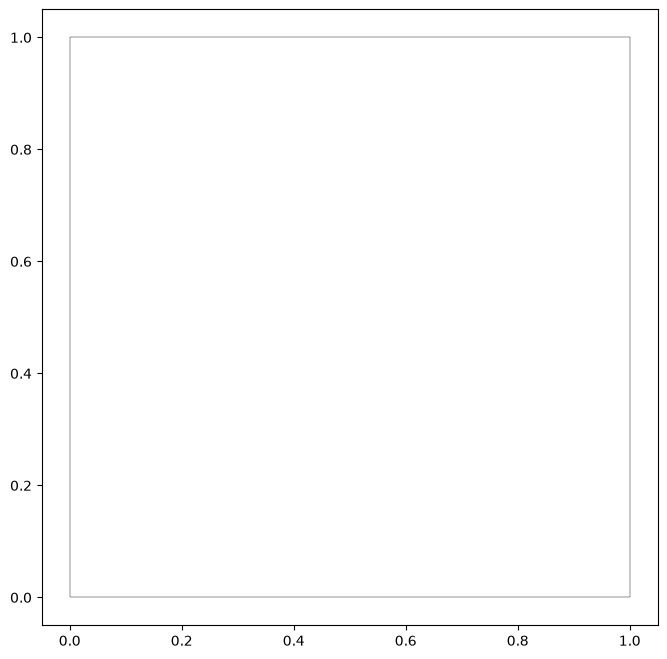

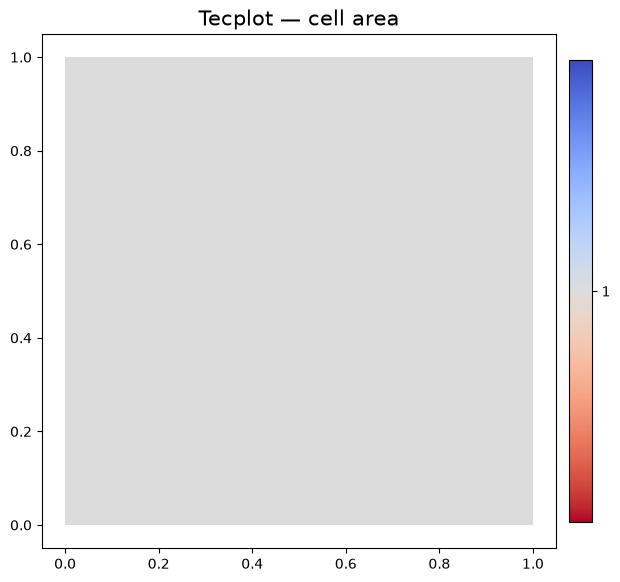

In [21]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="Tecplot — cell area"))

*A single quadrilateral element — the smallest valid FE zone — confirming the Tecplot zone parser builds a one-face mesh correctly.*

### 11. FLAC3D (`.f3grid`) — `driver="flac3d"`

FLAC3D `.f3grid` is the grid format of Itasca's geomechanics solver: `G` gridpoints and `Z` zones. An engineering grid in model units, no CRS.

In [22]:
ds = UgridDataset.read_file(str(DATA / "flac3d/flac3d_mesh_ex.f3grid"), driver="flac3d")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\flac3d\flac3d_mesh_ex.f3grid
  Mesh: mesh2d
  Nodes: 160, Faces: 108, Edges: 0
  Bounds: (0.0, 0.0, 2.0, 1.0)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(160,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 30 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,160,0.000000,1.500000,0.75625,0.497503
cell_area,108,0.001543,0.148148,0.06370,0.046167


Wireframe outline, then the same mesh coloured by per-cell area:

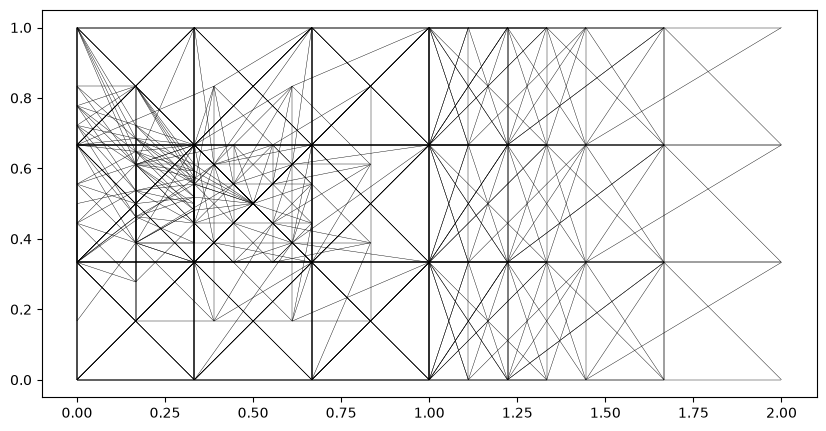

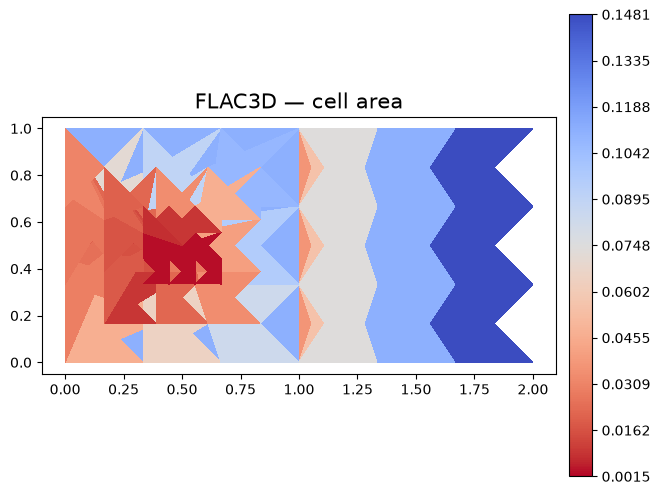

In [23]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="FLAC3D — cell area"))

*108 zones over 160 gridpoints; the wider area spread reflects a graded geomechanical grid, finer where stresses concentrate.*

### 12. Kratos (`.mdpa`) — `driver="kratos"`

Kratos `.mdpa` (ModelPart Data) feeds the Kratos Multiphysics framework: `Nodes` and `Elements` blocks. A multiphysics model file with no CRS.

In [24]:
ds = UgridDataset.read_file(str(DATA / "kratos/small_cube.mdpa"), driver="kratos")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\kratos\small_cube.mdpa
  Mesh: mesh2d
  Nodes: 8, Faces: 6, Edges: 0
  Bounds: (0.0, 0.0, 1.0, 1.0)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(8,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 3 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,8,0.0,1.0,0.5,0.5
cell_area,6,0.5,0.5,0.5,0.0


Wireframe outline, then the same mesh coloured by per-cell area:

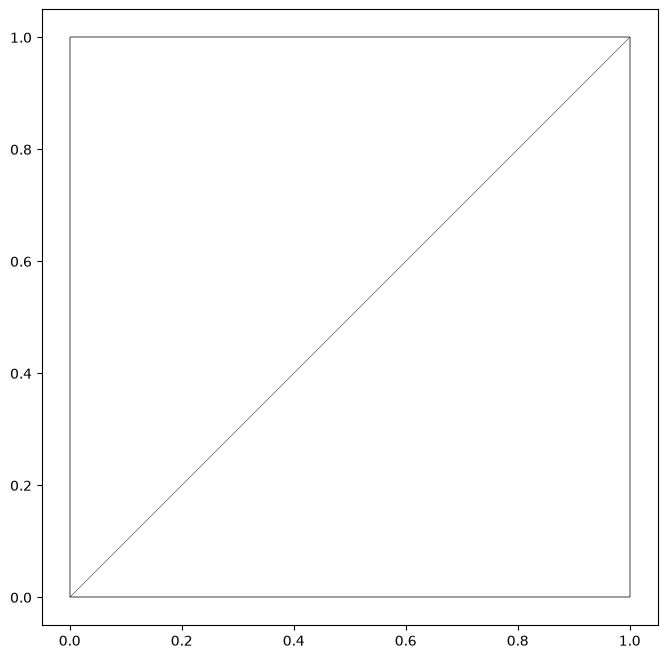

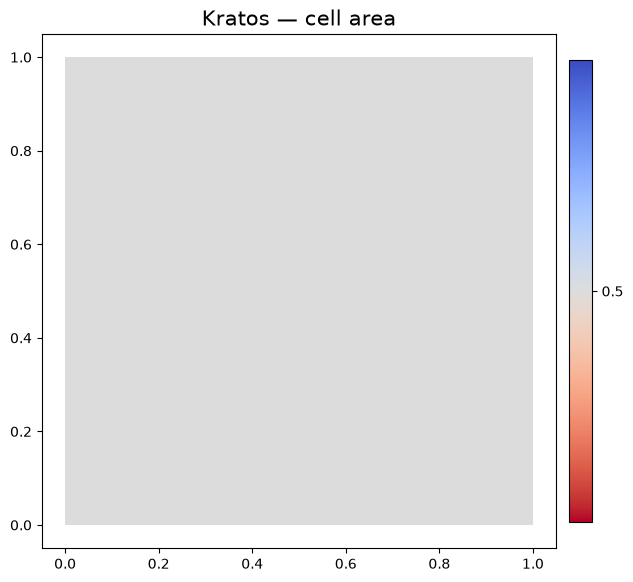

In [25]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="Kratos — cell area"))

*A minimal 8-node cube with six faces — the canonical Kratos unit test, read straight into a UgridDataset.*

### 13. Exodus II (`.exo`) — `driver="exodus"`

Exodus II (`.exo`) is the Sandia FE database format, NetCDF underneath, used by Trilinos, MOOSE and libMesh. A simulation database, carrying no CRS.

In [26]:
ds = UgridDataset.read_file(str(DATA / "exodus/geom_2.exo"), driver="exodus")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\exodus\geom_2.exo
  Mesh: mesh2d
  Nodes: 45, Faces: 96, Edges: 0
  Bounds: (-0.5000000000000001, -0.5000000000000001, 0.5000000000000001, 0.5000000000000001)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(45,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 40 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 16 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,45,0.1,1.1000,0.600000,0.408248
cell_area,96,0.0,0.0625,0.052083,0.023292


Wireframe outline, then the same mesh coloured by per-cell area:

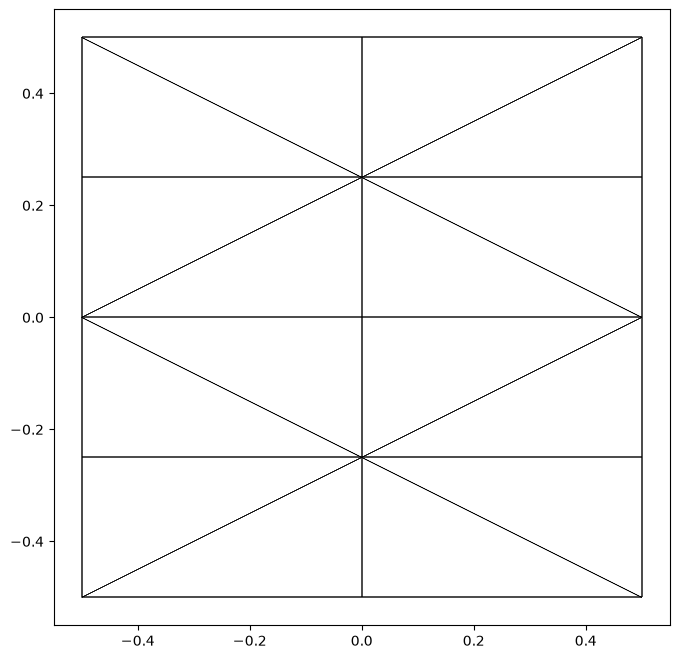

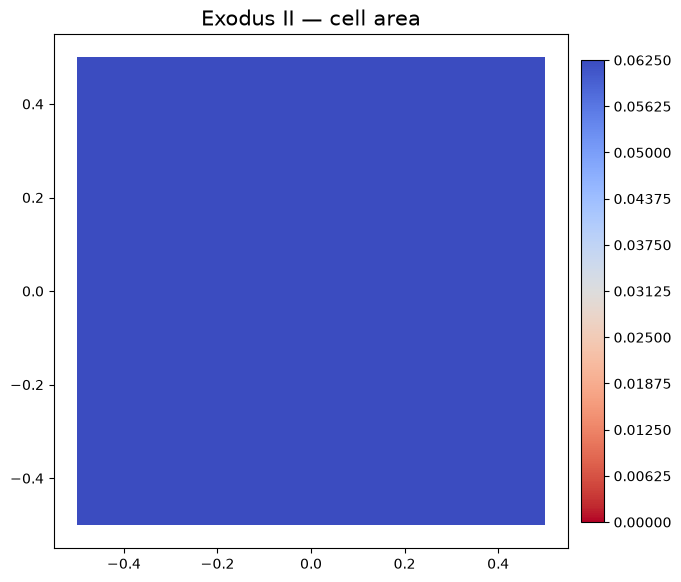

In [27]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="Exodus II — cell area"))

*A tetrahedral geometry shown by its 96 projected faces; Exodus riding on NetCDF is why pyramids' NetCDF lineage reads it comfortably.*

### 14. SU2 (`.su2`) — `driver="su2"`

SU2 `.su2` is the native mesh of the SU2 open-source CFD suite — a plain ASCII list of points and VTK-coded elements, 0-based. A CFD mesh, no CRS.

In [28]:
ds = UgridDataset.read_file(str(DATA / "su2/5x5Mesh.su2"), driver="su2")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\su2\5x5Mesh.su2
  Mesh: mesh2d
  Nodes: 36, Faces: 25, Edges: 0
  Bounds: (0.0, 0.0, 1.0, 1.0)
  CRS: unknown
  Data variables (0):
CRS: None


,count,min,max,mean,std
variable,,,,,
cell_area,25,0.04,0.04,0.04,3.663841e-17


Wireframe outline, then the same mesh coloured by per-cell area:

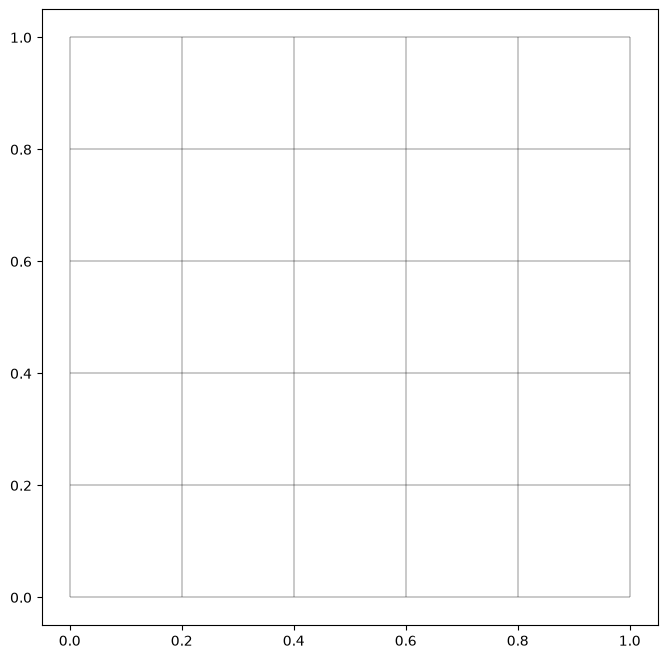

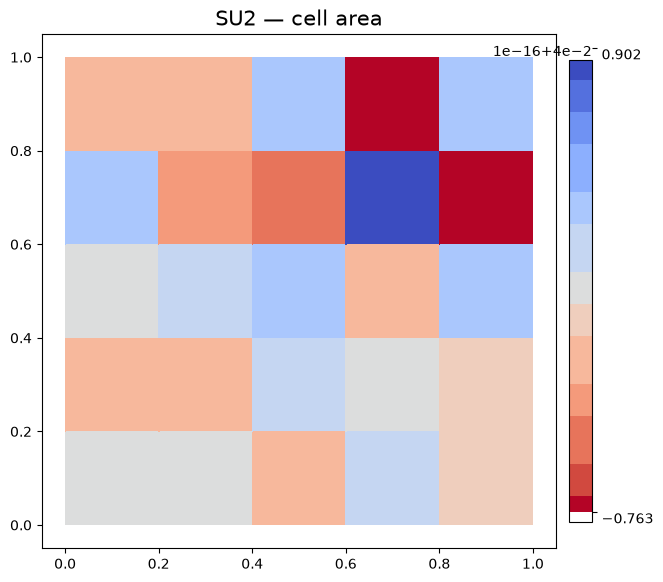

In [29]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="SU2 — cell area"))

*A tidy 5×5 quadrilateral grid; the constant 0.04 cell area confirms a perfectly structured unit-square mesh.*

### 15. Triangle / TetGen (`.node+.ele`) — `driver="triangle"`

Shewchuk's Triangle (and its 3-D cousin TetGen) split a mesh across `.node` and `.ele` files; passing the `.node` picks up the `.ele` sibling. A meshing-tool format, no CRS.

In [30]:
ds = UgridDataset.read_file(str(DATA / "triangle/mesh.node"), driver="triangle")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\triangle\mesh.node
  Mesh: mesh2d
  Nodes: 89, Faces: 304, Edges: 0
  Bounds: (0.0, 0.0, 1.0, 1.0)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(89,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 144 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 10 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,89,0.0,1.000000,0.488156,0.297577
cell_area,304,0.0,0.102842,0.024193,0.021642


Wireframe outline, then the same mesh coloured by per-cell area:

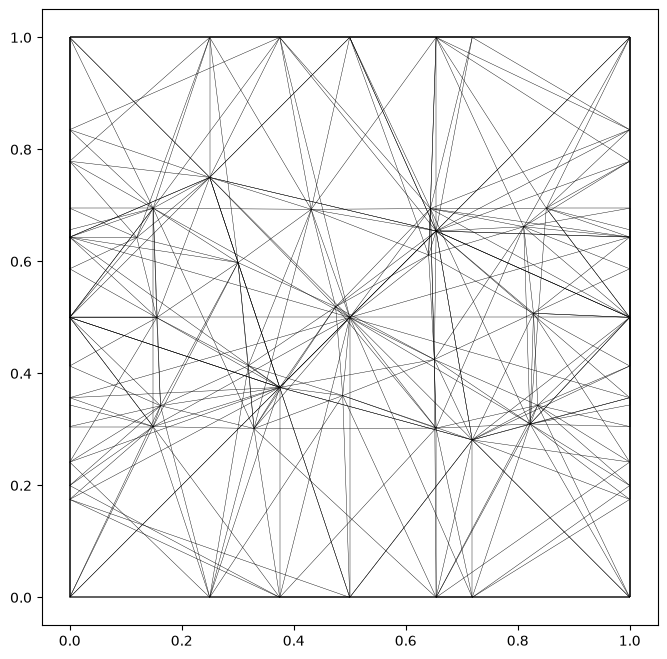

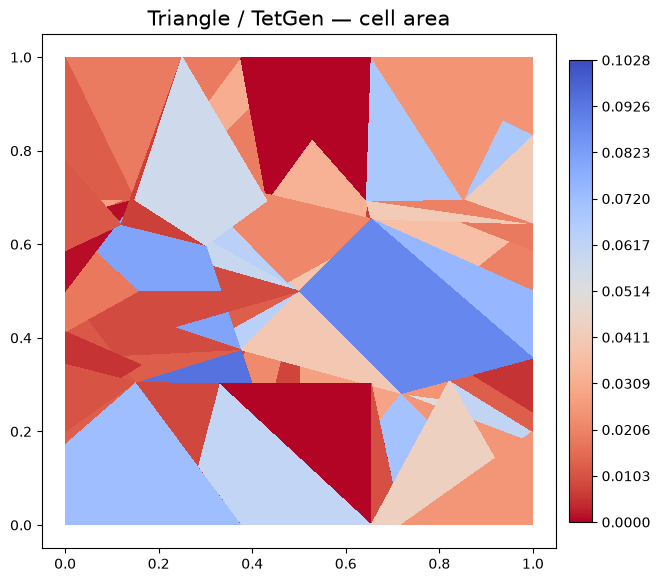

In [31]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="Triangle / TetGen — cell area"))

*304 triangles reconstructed from the paired node/element files — the driver stitches the two companion files into one mesh.*

### 16. OFF (`.off`) — `driver="off"`

OFF (Object File Format) is a minimal geometry-interchange format (Geomview, trimesh): a vertex list then a face list. Pure geometry, no CRS; inline comments and per-face colour are ignored.

In [32]:
ds = UgridDataset.read_file(str(DATA / "off/comments.off"), driver="off")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\off\comments.off
  Mesh: mesh2d
  Nodes: 8, Faces: 6, Edges: 0
  Bounds: (-1.632993, -1.632993, 1.632993, 1.632993)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(8,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 1 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 4 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,8,-1.154701,1.154701,0.000000,1.154701
cell_area,6,0.000000,5.333332,1.777777,2.514157


Wireframe outline, then the same mesh coloured by per-cell area:

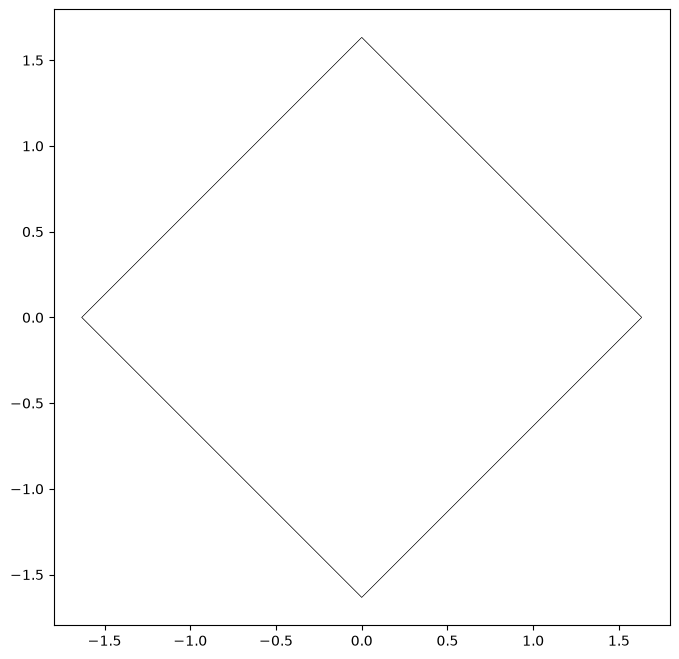

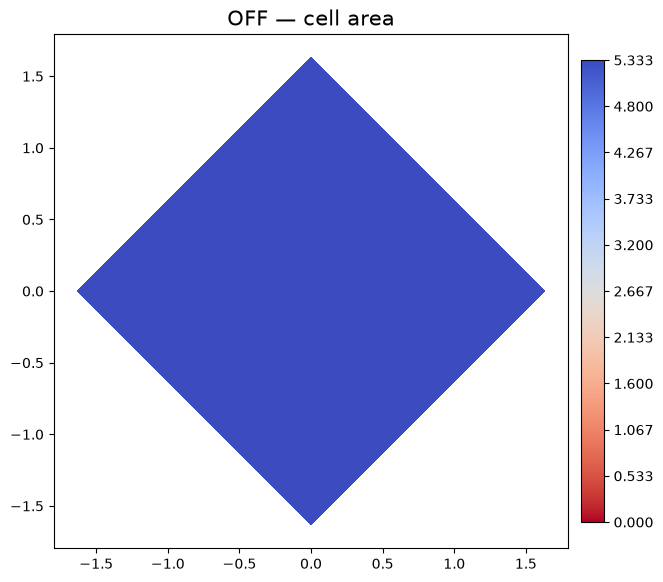

In [33]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="OFF — cell area"))

*A cube's six quad faces, parsed past its inline `#` comments and trailing RGBA colour — proof the reader tolerates optional OFF extras.*

### 17. GiD / Iber (`.msh`) — `driver="gid"`

GiD ASCII mesh (CIMNE format) is what the Iber 2-D hydraulic model exports (Iber is built on GiD). It shares the `.msh` suffix with Gmsh, so `driver="gid"` is required. No EPSG, so `crs=None`.

In [34]:
ds = UgridDataset.read_file(str(DATA / "gid/tube_2D_spline.GiD.msh"), driver="gid")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\gid\tube_2D_spline.GiD.msh
  Mesh: mesh2d
  Nodes: 943, Faces: 414, Edges: 0
  Bounds: (0.0, -20.0, 37.8843, 11.8444)
  CRS: unknown
  Data variables (0):
CRS: None


,count,min,max,mean,std
variable,,,,,
cell_area,414,0.117214,3.045124,0.929551,0.604511


Wireframe outline, then the same mesh coloured by per-cell area:

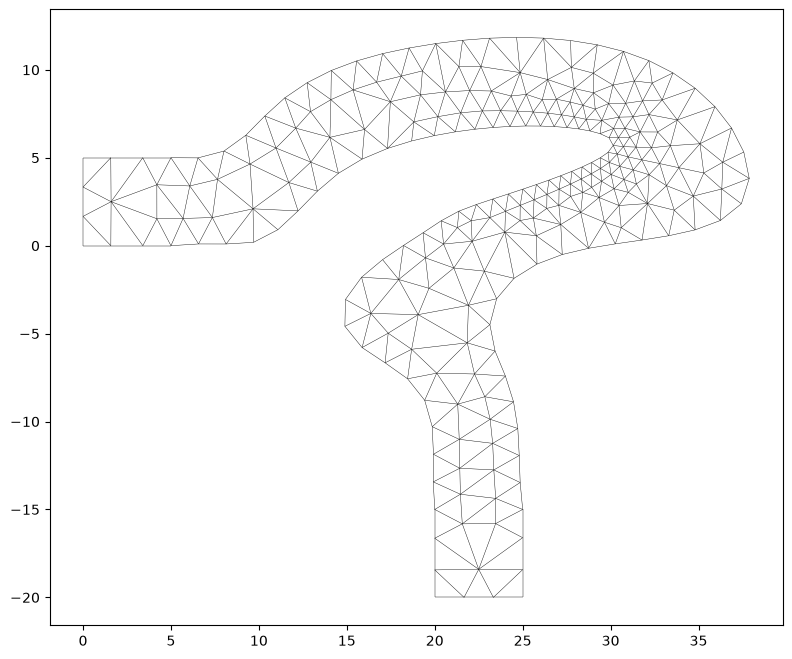

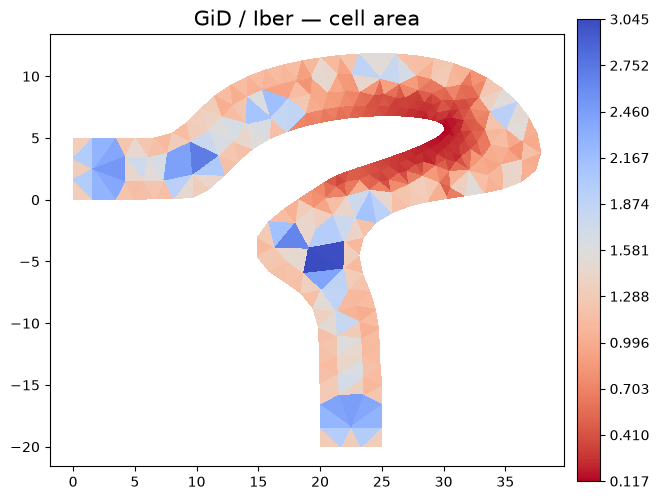

In [35]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="GiD / Iber — cell area"))

*414 triangles from a quadratic-triangle mesh — the reader keeps the three corner nodes of each 6-node element, giving a clean linear surface.*

### 18. OpenFOAM (`polyMesh/`) — `driver="openfoam"`

OpenFOAM stores a case mesh as a **directory** of ASCII files (`points`, `faces`, `owner`, ...) under `constant/polyMesh`, not a single file. Pass the directory with `driver="openfoam"`. A CFD mesh in metres, no CRS.

In [36]:
ds = UgridDataset.read_file(str(DATA / "openfoam/polyMesh"), driver="openfoam")
print(ds)
print("CRS:", ds.crs)
d = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d.summary()

UgridDataset: ..\..\examples\data\openfoam\polyMesh
  Mesh: mesh2d
  Nodes: 260, Faces: 258, Edges: 0
  Bounds: (-0.0003, 0.0, 0.0003, 0.06)
  CRS: unknown
  Data variables (1):
    node_z: location=node, shape=(260,)
CRS: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 64 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 130 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,260,-0.0003,3.000000e-04,0.000000e+00,3.000000e-04
cell_area,258,0.0000,5.625000e-07,2.790698e-07,2.812415e-07


Wireframe outline, then the same mesh coloured by per-cell area:

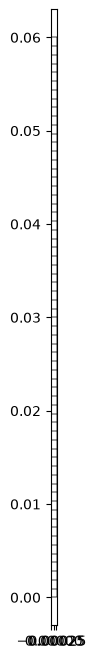

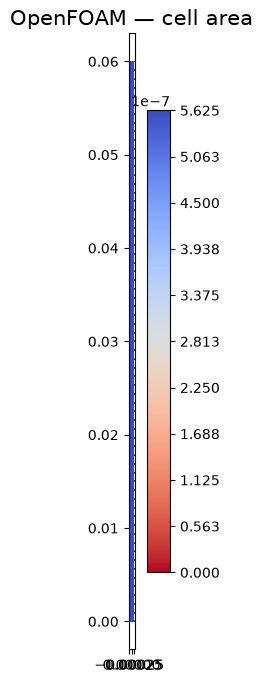

In [37]:
show(ds.plot_outline())
show(d.plot("cell_area", cmap="viridis", colorbar=True, title="OpenFOAM — cell area"))

*258 faces of an OpenFOAM finite-volume mesh; the very small projected areas (sub-micron) are because the model is defined in metres at a tiny physical scale.*

## Takeaways

- One API reads all eighteen formats: `UgridDataset.read_file(path, driver=...)`.
  The driver name is explicit here, but detection by suffix also works for most.
- HDF5-backed formats (CGNS, MED) need their driver named because they share
  suffixes with other readers; GiD needs it because `.msh` collides with Gmsh;
  OpenFOAM needs the *directory* path, not a file.
- Every mesh came in with `crs=None` — these are engineering models, not GIS
  layers. Loading them as `UgridDataset` objects is precisely what lets pyramids'
  GIS, sampling, regridding and plotting operate on them.
- `mesh.face_areas` plus `with_variable(...)` turns bare topology into something
  `summary()` and `plot()` can describe and colour — the bridge from a solver
  file to the pyramids analysis stack.